# Laboratory 2

## 1.4

### 1. (1D) Minimize $f(x)=x^4-4x^2+x$

Derivatives:

$$f'(x)=4x^3-8x+1,\qquad f''(x)=12x^2-8.$$

The critical points are the roots of $4x^3-8x+1=0$ (the polynomial has no rational roots, so they are computed numerically). The second-derivative test classifies each one: $f''>0$ local minimum, $f''<0$ local maximum.

The global minimum is the lowest of the local minima.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f   = lambda x: x**4 - 4*x**2 + x
fp  = lambda x: 4*x**3 - 8*x + 1
fpp = lambda x: 12*x**2 - 8

roots = np.sort(np.roots([4, 0, -8, 1]).real)

print(f"{'x*':>12} {'f(x*)':>12} {'f\'\'(x*)':>12}   classification")
for r in roots:
    kind = "local minimum" if fpp(r) > 0 else "local maximum"
    print(f"{r:12.6f} {f(r):12.6f} {fpp(r):12.6f}   {kind}")

x_global = roots[np.argmin(f(roots))]
print(f"\nGlobal minimum: x* = {x_global:.6f}, f(x*) = {f(x_global):.6f}")

          x*        f(x*)      f''(x*)   classification
   -1.472998    -5.444192    18.036663   local minimum
    0.126000     0.062748    -7.809487   local maximum
    1.346997    -2.618556    13.772824   local minimum

Global minimum: x* = -1.472998, f(x*) = -5.444192


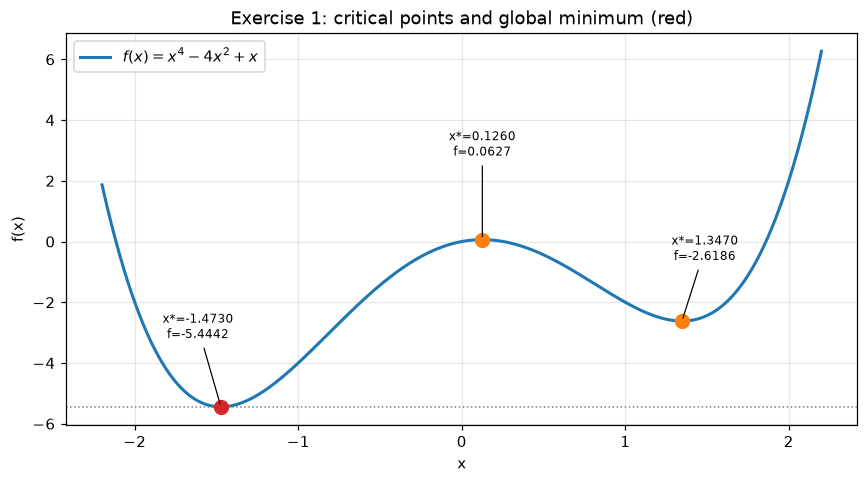

In [2]:
xs = np.linspace(-2.2, 2.2, 800)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, f(xs), lw=2, label=r"$f(x)=x^4-4x^2+x$")

offsets = [(-15, 45), (0, 55), (15, 40)]
for r, off in zip(roots, offsets):
    ax.scatter(r, f(r), s=80, zorder=3,
               color="tab:red" if r == x_global else "tab:orange")
    ax.annotate(f"x*={r:.4f}\nf={f(r):.4f}", (r, f(r)),
                textcoords="offset points", xytext=off, ha="center",
                fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.8))

ax.axhline(f(x_global), ls=":", color="gray", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Exercise 1: critical points and global minimum (red)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### 2. (2D) Minimize $f(x,y)=x^2+xy+y^2-4x-6y$

Gradient:

$$\nabla f(x,y)=\begin{bmatrix}2x+y-4\\ x+2y-6\end{bmatrix}.$$

Solving $\nabla f=0$:

$$\begin{cases}2x+y=4\\ x+2y=6\end{cases}\;\Longrightarrow\;(x^*,y^*)=\left(\tfrac{2}{3},\tfrac{8}{3}\right).$$

Hessian (constant):

$$H=\begin{bmatrix}2&1\\1&2\end{bmatrix},\qquad \lambda_1=1,\ \lambda_2=3>0.$$

$H$ is positive definite on all of $\mathbb{R}^2$, so the critical point is a strict local minimum and, since $f$ is a convex quadratic, it is also the **global minimum**. Minimum value: $f(2/3,8/3)=-28/3\approx-9.3333$.

In [3]:
grad = lambda x, y: np.array([2*x + y - 4, x + 2*y - 6])
f2   = lambda x, y: x**2 + x*y + y**2 - 4*x - 6*y

H = np.array([[2.0, 1.0], [1.0, 2.0]])
p = np.linalg.solve(H, np.array([4.0, 6.0]))

print("Critical point (x*, y*) =", p)
print("∇f(x*, y*) =", grad(*p))
print("Hessian:\n", H)
print("Eigenvalues:", np.linalg.eigvalsh(H))
print("D = f_xx f_yy - f_xy² =", np.linalg.det(H))
print(f"f(x*, y*) = {f2(*p):.6f}")

Critical point (x*, y*) = [0.66666667 2.66666667]
∇f(x*, y*) = [0. 0.]
Hessian:
 [[2. 1.]
 [1. 2.]]
Eigenvalues: [1. 3.]
D = f_xx f_yy - f_xy² = 2.9999999999999996
f(x*, y*) = -9.333333


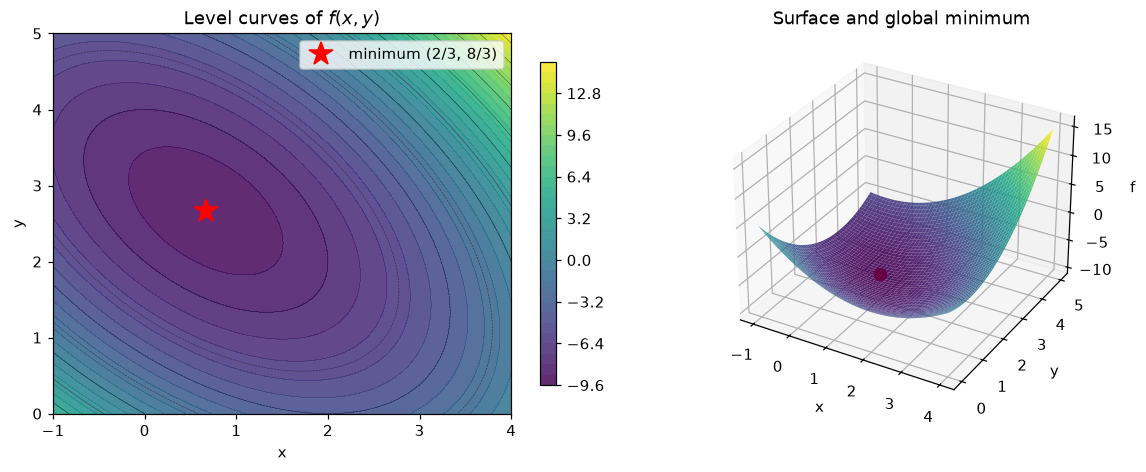

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

gx, gy = np.meshgrid(np.linspace(-1, 4, 150), np.linspace(0, 5, 150))
gz = f2(gx, gy)

fig = plt.figure(figsize=(11, 4.4))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(gx, gy, gz, levels=30, cmap="viridis", alpha=0.85)
ax1.contour(gx, gy, gz, levels=15, colors="k", linewidths=0.4, alpha=0.5)
ax1.plot(*p, "r*", ms=16, label=r"minimum $(2/3,\,8/3)$")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Level curves of $f(x,y)$")
ax1.legend(); fig.colorbar(cf, ax=ax1, shrink=0.85)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(gx, gy, gz, cmap="viridis", alpha=0.9, linewidth=0)
ax2.scatter(*p, f2(*p), color="red", s=60, zorder=5)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("f")
ax2.set_title("Surface and global minimum")

plt.tight_layout(); plt.show()

## Brief conclusions

- **1D:** there are three critical points: two local minima ($x\approx-1.4730$ and $x\approx1.3470$) and one local maximum ($x\approx0.1260$). The global minimum is $x^*\approx-1.4730$ with $f(x^*)\approx-5.4442$, since the function grows to $+\infty$ at both ends.
- **2D:** the only critical point is $(2/3,\,8/3)$; the constant positive-definite Hessian guarantees that it is the global minimum, with $f_{\min}=-28/3$.

---

## 2.2 Python exercise: pseudoinverse vs `lstsq`

The goal is to numerically solve

$$\min_x \|Ax-y\|_2^2$$

in two ways: with the pseudoinverse (`np.linalg.pinv(A) @ y`) and with `np.linalg.lstsq`. We also compare two regimes:

- **Overdetermined** ($m>n$): there are more measurements than unknowns; normally a unique least-squares solution exists.
- **Underdetermined** ($m<n$): there are fewer measurements than unknowns; there are infinitely many solutions that fit the data, and the pseudoinverse returns the one with **minimum norm**.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

SIGMA = 0.05


def run_case(m, n, seed):
    # Generate y = A x_true + noise and solve with pinv and lstsq.
    rng = np.random.default_rng(seed)

    A = rng.standard_normal((m, n))
    x_true = rng.standard_normal(n)
    y = A @ x_true + SIGMA * rng.standard_normal(m)

    x_pinv = np.linalg.pinv(A) @ y
    x_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]

    def relative_error(x):
        return np.linalg.norm(x - x_true) / np.linalg.norm(x_true)

    def residual(x):
        return np.linalg.norm(A @ x - y)

    return {
        "m": m, "n": n,
        "A": A, "x_true": x_true, "y": y,
        "x_pinv": x_pinv, "x_lstsq": x_lstsq,
        "rel_pinv": relative_error(x_pinv),
        "rel_lstsq": relative_error(x_lstsq),
        "res_pinv": residual(x_pinv),
        "res_lstsq": residual(x_lstsq),
    }


cases = {
    "m > n": run_case(80, 20, seed=1),
    "m < n": run_case(20, 80, seed=2),
}

print(f"{'case':<6} {'method':<8} {'rel. error':>12} {'residual':>12}")
print("-" * 42)
for name, r in cases.items():
    print(f"{name:<6} {'pinv':<8} {r['rel_pinv']:12.3e} {r['res_pinv']:12.3e}")
    print(f"{'':<6} {'lstsq':<8} {r['rel_lstsq']:12.3e} {r['res_lstsq']:12.3e}")

print("\nMaximum difference between pinv and lstsq:")
for name, r in cases.items():
    diff = np.linalg.norm(r["x_pinv"] - r["x_lstsq"])
    print(f"  {name}: {diff:.2e}")

case   method     rel. error     residual
------------------------------------------
m > n  pinv        4.471e-03    4.148e-01
       lstsq       4.471e-03    4.148e-01
m < n  pinv        8.928e-01    4.759e-14
       lstsq       8.928e-01    4.578e-14

Maximum difference between pinv and lstsq:
  m > n: 1.01e-14
  m < n: 5.46e-15


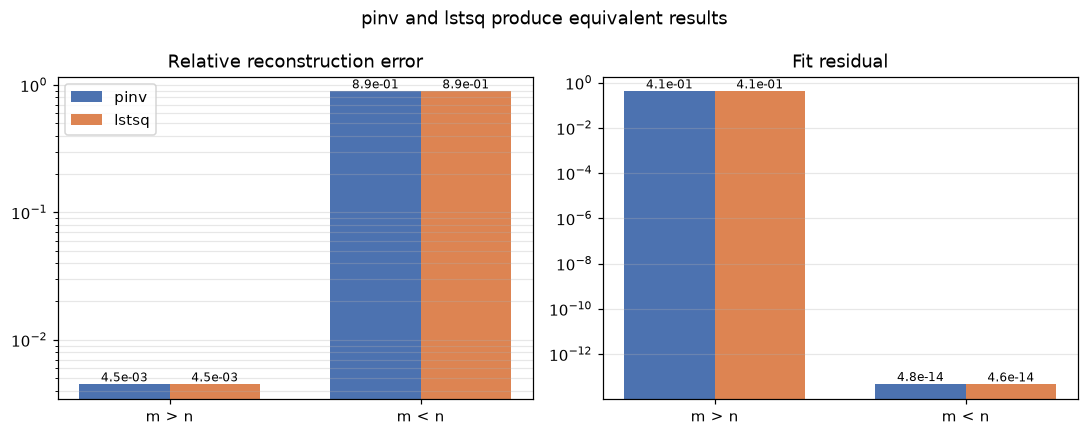

In [6]:
names = list(cases.keys())
pos = np.arange(len(names))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, key, title in zip(
    axes,
    ["rel", "res"],
    ["Relative reconstruction error", "Fit residual"],
):
    values_pinv = [cases[k][key + "_pinv"] for k in names]
    values_lstsq = [cases[k][key + "_lstsq"] for k in names]

    ax.bar(pos - width / 2, values_pinv, width,
           label="pinv", color="#4C72B0")
    ax.bar(pos + width / 2, values_lstsq, width,
           label="lstsq", color="#DD8452")

    ax.set_xticks(pos, ["m > n", "m < n"])
    ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", which="both", alpha=0.3)

    for x, v in zip(pos - width / 2, values_pinv):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)
    for x, v in zip(pos + width / 2, values_lstsq):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)

axes[0].legend()
fig.suptitle("pinv and lstsq produce equivalent results")
fig.tight_layout()
plt.show()

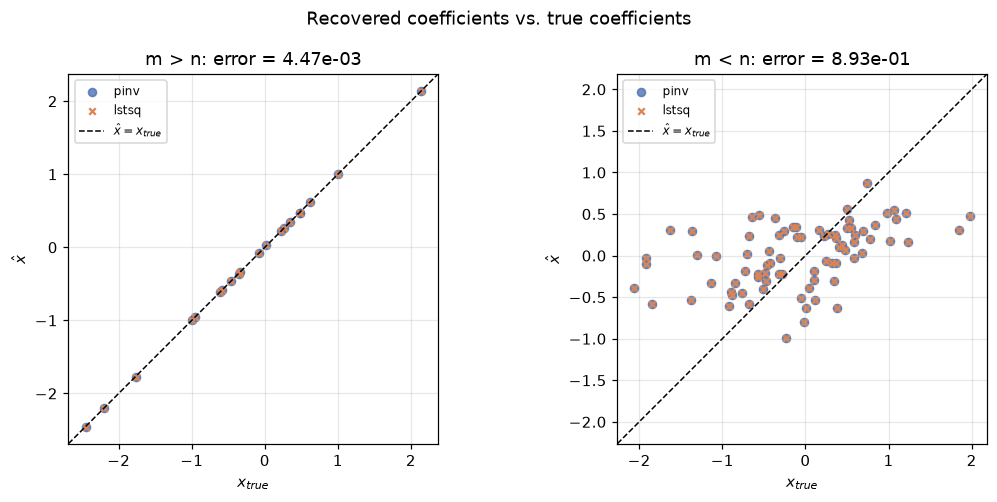

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

for ax, (name, r) in zip(axes, cases.items()):
    ax.scatter(r["x_true"], r["x_pinv"], s=28, alpha=0.8,
               label="pinv", color="#4C72B0")
    ax.scatter(r["x_true"], r["x_lstsq"], s=18, marker="x",
               label="lstsq", color="#DD8452")

    minimum = min(r["x_true"].min(), r["x_pinv"].min(), r["x_lstsq"].min())
    maximum = max(r["x_true"].max(), r["x_pinv"].max(), r["x_lstsq"].max())
    margin = 0.05 * (maximum - minimum)

    ax.plot([minimum - margin, maximum + margin],
            [minimum - margin, maximum + margin],
            "k--", lw=1, label=r"$\hat{x}=x_{true}$")

    ax.set_xlim(minimum - margin, maximum + margin)
    ax.set_ylim(minimum - margin, maximum + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x_{true}$")
    ax.set_ylabel(r"$\hat{x}$")
    ax.set_title(f"{name}: error = {r['rel_pinv']:.2e}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Recovered coefficients vs. true coefficients")
fig.tight_layout()
plt.show()

### Observations

- `pinv` and `lstsq` agree to machine precision in both cases.
- **Case $m>n$:** the system has a unique least-squares solution; the relative error is small ($\approx 4.5\times10^{-3}$) and the residual is on the order of the noise.
- **Case $m<n$:** the residual is essentially zero because the noise can always be fitted exactly, but the relative error is large ($\approx 0.89$). The pseudoinverse returns the **minimum-norm** solution, not the true one; recovering it would require additional information or regularization.
- For $m<n$, $\|x_{pinv}\|=3.35$ compared with $\|x_{true}\|=7.46$; another solution that also fits the data can have norm $15.30$ and residual $\sim10^{-14}$. This confirms that `pinv` chooses the minimum-norm solution.
- Both systems are well conditioned ($\text{cond}(A)\approx 3$): for $m<n$ the problem is not one of numerical ill-conditioning, but of **lack of information**.


---

## 3.1 Exercise: deconvolution and instability

The linear inverse problem is

$$y = Ax + e,$$

where $x=\operatorname{vec}(X)\in\mathbb{R}^{N}$ is the unknown image, $A\in\mathbb{R}^{N\times N}$ is the Gaussian blur operator, $e\sim\mathcal{N}(0,\sigma_\eta^2 I)$ is the measurement noise and $y$ is the observed (blurred) data. The forward problem blurs; the inverse problem tries to undo the blur.

**Setup.** The image is the grayscale `skimage.data.camera()`, resized to $48\times48$ and normalized to $[0,1]$. The kernel is Gaussian of size $9\times9$ with $\sigma_k=1.5$, and the boundary rule is symmetric (`boundary="symm"`). The matrix is built explicitly, column by column, exactly as suggested in the guide:

$$A_{:,j}=\operatorname{vec}\big(\operatorname{blur}(E_j)\big),\qquad E_j=\text{image that is zero except for a }1\text{ at pixel }j.$$

Since the kernel and the boundary rule are symmetric, $A$ is symmetric, so its singular values are $|\lambda_i(A)|$.

### 1. Image, kernel and explicit blur matrix


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from skimage import data, transform
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. Grayscale image, resized and normalized to [0, 1].
X = data.camera().astype(float) / 255.0
X = transform.resize(X, (48, 48), anti_aliasing=True)
X = X / X.max()

h, w = X.shape
N = h * w
print(f"Image: {h}x{w} = {N} pixels, range [{X.min():.2f}, {X.max():.2f}]")


# 2. Normalized Gaussian kernel of odd size (2r+1)x(2r+1).
def gaussian_kernel(size=9, sigma=1.5):
    r = size // 2
    ax = np.arange(-r, r + 1)
    xx, yy = np.meshgrid(ax, ax)
    K = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return K / K.sum()


K = gaussian_kernel(size=9, sigma=1.5)


def blur_image(Z):
    return convolve2d(Z, K, mode="same", boundary="symm")


# 3. Build A column by column: A[:, j] = vec(blur(E_j)).
A = np.empty((N, N))
for j in range(N):
    E = np.zeros((h, w))
    E.flat[j] = 1.0
    A[:, j] = blur_image(E).ravel()

print(f"A: {A.shape}, {A.size:,} entries, {np.count_nonzero(A):,} nonzeros")
print(f"Symmetry error max|A - A^T| = {np.abs(A - A.T).max():.2e}")
print(f"Kernel sum = {K.sum():.6f}")


Image: 48x48 = 2304 pixels, range [0.02, 1.00]
A: (2304, 2304), 5,308,416 entries, 169,744 nonzeros
Symmetry error max|A - A^T| = 2.78e-17
Kernel sum = 1.000000



Each column of $A$ is the blur of a single-pixel impulse, so the matrix is a discrete convolution operator. The construction is transparent but expensive: $A$ has $N^2$ entries, which is why the image is kept small.

### 2. Pseudoinverse reconstructions

We compute one SVD of $A$ and reuse it everywhere. The pseudoinverse solution

$$\hat{x}=A^{\dagger}y=V\Sigma^{-1}U^{\top}y$$

is mathematically identical to `np.linalg.pinv(A) @ y`, but computing the SVD once lets us inspect the spectrum and build the regularized solutions of the last part for free.


In [9]:
# One SVD gives the pseudoinverse, the spectrum, and the regularized solutions.
U, s, Vt = np.linalg.svd(A, full_matrices=False)


def solve_pinv(y):
    """Return V S^{-1} U^T y, i.e. the same result as np.linalg.pinv(A) @ y."""
    return Vt.T @ ((U.T @ y) / s)


# 4. Noiseless and noisy measurements.
x = X.ravel()
y = A @ x

SIGMA_ETA = 0.005
rng = np.random.default_rng(1)
e = SIGMA_ETA * rng.standard_normal(N)
y_eta = y + e

# 5. Naive reconstructions from both data sets.
x_clean = solve_pinv(y)
x_noisy = solve_pinv(y_eta)

# 6. Noise of the same variance added BEFORE the forward model.
x_pre = solve_pinv(A @ (x + e))

print(f"cond(A) = {s[0] / s[-1]:.2e}   "
      f"(sigma_max = {s[0]:.3f}, sigma_min = {s[-1]:.2e})")
print(f"relative data error ||e||/||y|| = {np.linalg.norm(e) / np.linalg.norm(y):.3e}")
print(f"amplification ||x_noisy - x|| / ||e|| = "
      f"{np.linalg.norm(x_noisy - x) / np.linalg.norm(e):.2e}")
print(f"max |pinv(A(x+e)) - (x+e)| = {np.abs(x_pre - (x + e)).max():.2e}")
print(f"max |pinv(Ax) - x|         = {np.abs(x_clean - x).max():.2e}")
print()

rows = [
    ("blurred measurement y", y),
    ("pinv(y), noiseless", x_clean),
    ("noisy measurement y+e", y_eta),
    ("pinv(y+e)", x_noisy),
    ("image with noise x+e", x + e),
    ("pinv(A(x+e))", x_pre),
]
print(f"{'reconstruction':26s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 46)
for name, z in rows:
    Z = z.reshape(h, w)
    print(f"{name:26s} {psnr(X, Z, data_range=1.0):10.2f} "
          f"{ssim(X, Z, data_range=1.0):7.3f}")


cond(A) = 2.44e+08   (sigma_max = 1.000, sigma_min = 4.09e-09)
relative data error ||e||/||y|| = 7.962e-03
amplification ||x_noisy - x|| / ||e|| = 4.38e+06
max |pinv(A(x+e)) - (x+e)| = 1.25e-09
max |pinv(Ax) - x|         = 1.73e-09

reconstruction              PSNR (dB)    SSIM
----------------------------------------------
blurred measurement y           23.49   0.812
pinv(y), noiseless             187.72   1.000
noisy measurement y+e           23.45   0.804
pinv(y+e)                      -86.90   0.000
image with noise x+e            45.94   0.993
pinv(A(x+e))                    45.94   0.993


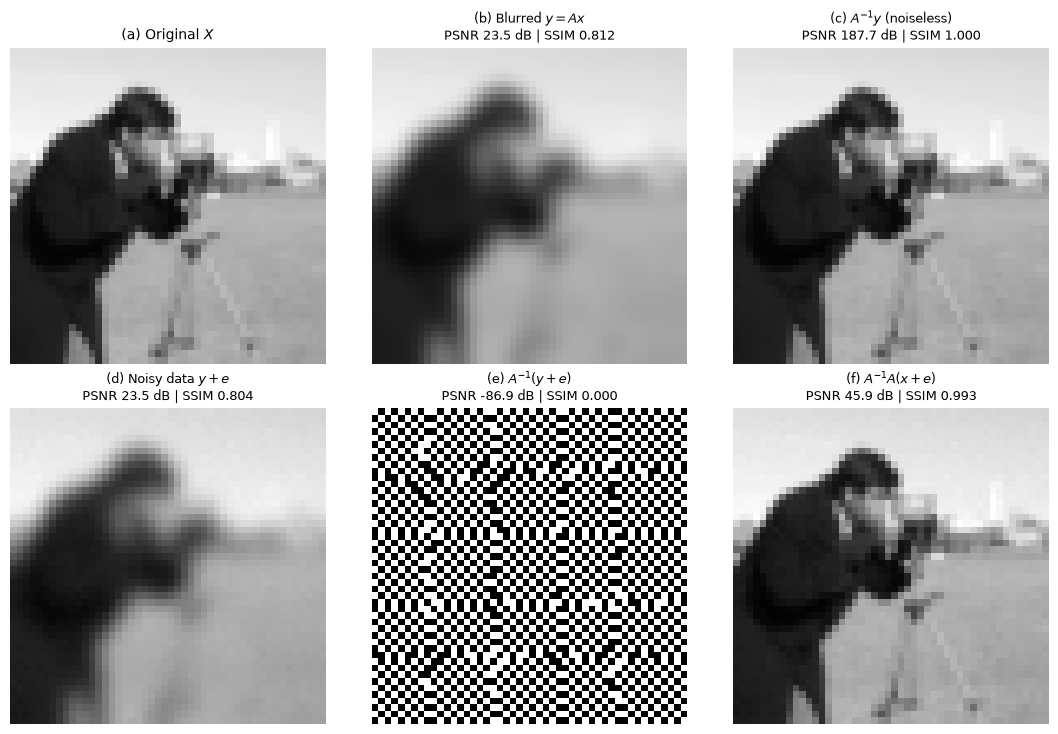

In [10]:
panels = [
    ("(a) Original $X$", X, None),
    ("(b) Blurred $y = Ax$", y.reshape(h, w), y),
    ("(c) $A^{-1}y$ (noiseless)", x_clean.reshape(h, w), x_clean),
    ("(d) Noisy data $y+e$", y_eta.reshape(h, w), y_eta),
    ("(e) $A^{-1}(y+e)$", x_noisy.reshape(h, w), x_noisy),
    ("(f) $A^{-1}A(x+e)$", x_pre.reshape(h, w), x_pre),
]

fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, img, vec) in zip(axes.ravel(), panels):
    # The unstable reconstruction is clipped to [0, 1] only for display.
    ax.imshow(np.clip(img, 0, 1), cmap="gray", vmin=0, vmax=1)
    if vec is None:
        ax.set_title(title, fontsize=10)
    else:
        p, q = psnr(X, vec.reshape(h, w), data_range=1.0), \
               ssim(X, vec.reshape(h, w), data_range=1.0)
        ax.set_title(f"{title}\nPSNR {p:.1f} dB | SSIM {q:.3f}", fontsize=9)
    ax.axis("off")

fig.tight_layout()



**Figure 1.** Three experiments required by the exercise: (b) noiseless blurred data, (d) noise added to the measurement after blurring, and (f) noise added to the original image before blurring. Panel (e) is clipped to $[0,1]$ only for display; its actual values reach about $8\times10^{4}$.

- **Noiseless data:** the inversion is essentially perfect (PSNR $187.7$ dB, SSIM $1.000$). Since $y=Ax$ lies exactly in the range of $A$, there is no noise to amplify.
- **Noise in the measurement:** adding noise of standard deviation $0.005$ (PSNR $45.9$ dB with respect to the image) leaves the blurred measurement visually unchanged, yet it completely destroys the reconstruction (PSNR $-86.9$ dB). The result is pure high-frequency garbage.
- **Noise in the original image:** if the same noise is added *before* blurring, the reconstruction is $\hat{x}=A^{-1}A(x+e)=x+e$, i.e. the original image plus noise (PSNR $45.9$ dB). The inversion does not amplify it; the blur simply forwards it. The numerical check `max |pinv(A(x+e)) - (x+e)| ~ 1e-8` confirms this identity.

The comparison isolates the real problem: the inversion itself amplifies noise, it does not create it.



### 3. Why does a tiny noise destroy the reconstruction?

The error of the direct inversion is governed by the smallest singular value of $A$:

$$\hat{x}-x=A^{-1}(y+e)-A^{-1}y=A^{-1}e,$$

so

$$\frac{\|\hat{x}-x\|_2}{\|x\|_2}\;\le\;\|A^{-1}\|_2\,\frac{\|e\|_2}{\|x\|_2}\;=\;\frac{1}{\sigma_{\min}}\frac{\|e\|}{\|y\|}\frac{\|y\|}{\|x\|}\;\le\;\operatorname{cond}(A)\,\frac{\|e\|}{\|y\|}.$$

With $\operatorname{cond}(A)\approx2.4\times10^{8}$ and relative data error $\delta=\|e\|/\|y\|\approx8.0\times10^{-3}$, the worst-case bound is $\operatorname{cond}(A)\,\delta\approx1.9\times10^{6}$. The measured relative reconstruction error is $\approx3.4\times10^{4}$, about $4\times10^{6}$ times the relative data error, and the measured amplification $\|\hat{x}-x\|/\|e\|$ is $\approx4.4\times10^{6}$. The noise components along the singular directions with $\sigma_i<\sigma_\eta$ are divided by $\sigma_i\approx10^{-9}$, which produces the checkerboard pattern in Figure 1(e).


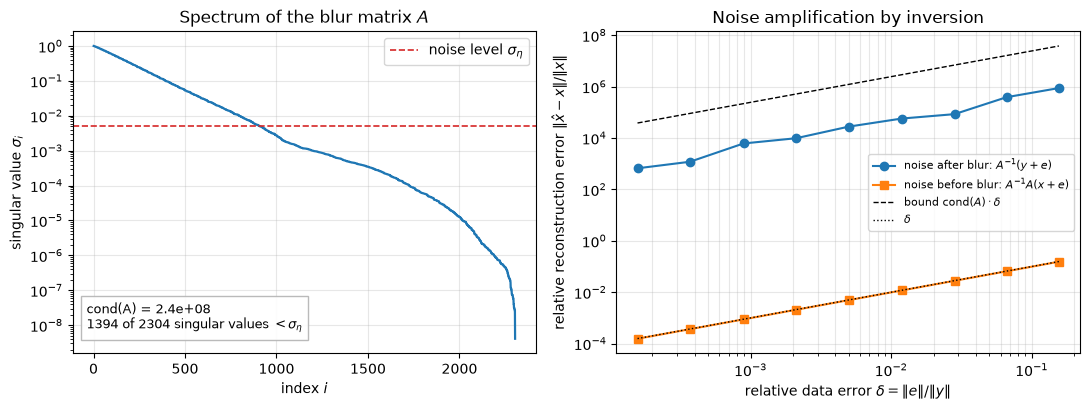

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: singular-value spectrum of the blur matrix.
ax1.semilogy(np.arange(1, N + 1), s, lw=1.6)
ax1.axhline(SIGMA_ETA, color="tab:red", ls="--", lw=1.2,
            label=r"noise level $\sigma_\eta$")
ax1.set_xlabel("index $i$")
ax1.set_ylabel(r"singular value $\sigma_i$")
ax1.set_title("Spectrum of the blur matrix $A$")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper right")
n_bad = int(np.sum(s < SIGMA_ETA))
ax1.text(0.03, 0.06,
         f"cond(A) = {s[0] / s[-1]:.1e}\n"
         f"{n_bad} of {N} singular values $<\\sigma_\\eta$",
         transform=ax1.transAxes, fontsize=9, va="bottom",
         bbox=dict(fc="white", ec="0.7", alpha=0.9))

# Right: reconstruction error vs data error, for noise added after/before blur.
sigmas = np.logspace(-4, -1, 9)
trials = 5
rel_data = np.zeros((trials, len(sigmas)))
rel_after = np.zeros((trials, len(sigmas)))
rel_before = np.zeros((trials, len(sigmas)))

rng_sweep = np.random.default_rng(7)
for i, sig in enumerate(sigmas):
    for t in range(trials):
        e_t = sig * rng_sweep.standard_normal(N)
        rel_data[t, i] = np.linalg.norm(e_t) / np.linalg.norm(y)
        rel_after[t, i] = np.linalg.norm(solve_pinv(y + e_t) - x) / np.linalg.norm(x)
        rel_before[t, i] = np.linalg.norm(solve_pinv(A @ (x + e_t)) - x) / np.linalg.norm(x)

ax2.loglog(rel_data.mean(0), rel_after.mean(0), "o-",
           label="noise after blur: $A^{-1}(y+e)$")
ax2.loglog(rel_data.mean(0), rel_before.mean(0), "s-",
           label="noise before blur: $A^{-1}A(x+e)$")
ax2.loglog(rel_data.mean(0), (s[0] / s[-1]) * rel_data.mean(0), "k--", lw=1,
           label=r"bound $\mathrm{cond}(A)\cdot\delta$")
ax2.loglog(rel_data.mean(0), rel_data.mean(0), "k:", lw=1,
           label=r"$\delta$")
ax2.set_xlabel(r"relative data error $\delta=\|e\|/\|y\|$")
ax2.set_ylabel(r"relative reconstruction error $\|\hat{x}-x\|/\|x\|$")
ax2.set_title("Noise amplification by inversion")
ax2.grid(alpha=0.3, which="both")
ax2.legend(fontsize=8)

fig.tight_layout()



**Figure 2.** Left: singular values of $A$ span more than eight orders of magnitude, and 1394 of the 2304 singular values lie below the noise level. The components associated with those directions cannot be recovered from noisy data. Right: both curves have slope one. Noise added after blurring is amplified by about six orders of magnitude at the largest noise levels (the dashed worst-case bound $\operatorname{cond}(A)\,\delta$ lies about two orders of magnitude higher), whereas noise added before blurring coincides with the diagonal $\delta$: it is propagated without amplification.



### 4. A first cure: truncating or damping the small singular values

The instability comes from dividing by $\sigma_i\approx0$. Two classical ways to avoid it are:

- **Truncated SVD (TSVD):** keep only the $k$ largest singular values,
  $$\hat{x}_k=\sum_{i=1}^{k}\frac{u_i^{\top}y}{\sigma_i}\,v_i .$$
- **Tikhonov regularization:** replace $1/\sigma_i$ by the filtered factor $\sigma_i/(\sigma_i^2+\lambda)$,
  $$\hat{x}_\lambda=\sum_{i=1}^{N}\frac{\sigma_i}{\sigma_i^2+\lambda}\,(u_i^{\top}y)\,v_i .$$

Both trade a little bias for a large reduction in variance. The best $k$ and $\lambda$ below are chosen by maximizing PSNR on this example (an oracle choice); in practice one uses the discrepancy principle or cross-validation. This is only a preview; the wavelet prior plus ISTA (Section 4 of the workshop) is the proper regularized solver.


TSVD      : k =  584      PSNR =  27.17 dB   SSIM = 0.790
Tikhonov  : lambda = 2.2e-03   PSNR =  27.87 dB   SSIM = 0.853
Direct    :                 PSNR = -86.90 dB   SSIM = 0.000


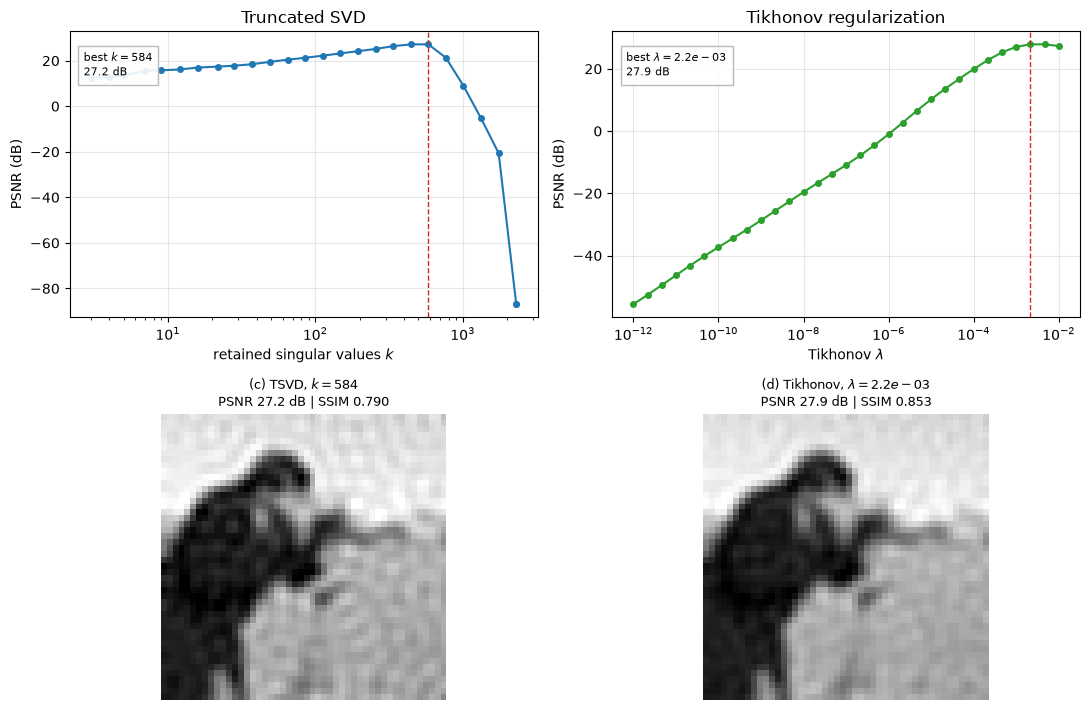

In [12]:
ks = np.unique(np.round(np.logspace(0.5, np.log10(N), 25)).astype(int))
ks = np.append(ks, N)
psnr_k = []
for k in ks:
    x_k = Vt[:k].T @ ((U[:, :k].T @ y_eta) / s[:k])
    psnr_k.append(psnr(X, x_k.reshape(h, w), data_range=1.0))

lams = np.logspace(-12, -2, 31)
psnr_l = []
for lam in lams:
    filt = s / (s**2 + lam)
    x_l = Vt.T @ (filt * (U.T @ y_eta))
    psnr_l.append(psnr(X, x_l.reshape(h, w), data_range=1.0))

k_best = ks[int(np.argmax(psnr_k))]
lam_best = lams[int(np.argmax(psnr_l))]

x_tsvd = Vt[:k_best].T @ ((U[:, :k_best].T @ y_eta) / s[:k_best])
x_tik = Vt.T @ (s / (s**2 + lam_best) * (U.T @ y_eta))

p_tsvd, q_tsvd = psnr(X, x_tsvd.reshape(h, w), data_range=1.0), \
                 ssim(X, x_tsvd.reshape(h, w), data_range=1.0)
p_tik, q_tik = psnr(X, x_tik.reshape(h, w), data_range=1.0), \
               ssim(X, x_tik.reshape(h, w), data_range=1.0)

print(f"TSVD      : k = {k_best:4d}      PSNR = {p_tsvd:6.2f} dB   SSIM = {q_tsvd:.3f}")
print(f"Tikhonov  : lambda = {lam_best:.1e}   PSNR = {p_tik:6.2f} dB   SSIM = {q_tik:.3f}")
print(f"Direct    :                 PSNR = "
      f"{psnr(X, x_noisy.reshape(h, w), data_range=1.0):6.2f} dB   "
      f"SSIM = {ssim(X, x_noisy.reshape(h, w), data_range=1.0):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7.2))

axes[0, 0].semilogx(ks, psnr_k, "o-", ms=4)
axes[0, 0].axvline(k_best, color="tab:red", ls="--", lw=1)
axes[0, 0].set_xlabel("retained singular values $k$")
axes[0, 0].set_ylabel("PSNR (dB)")
axes[0, 0].set_title("Truncated SVD")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].text(0.03, 0.93, f"best $k={k_best}$\n{max(psnr_k):.1f} dB",
                transform=axes[0, 0].transAxes, fontsize=8, va="top",
                bbox=dict(fc="white", ec="0.7", alpha=0.9))

axes[0, 1].semilogx(lams, psnr_l, "o-", ms=4, color="tab:green")
axes[0, 1].axvline(lam_best, color="tab:red", ls="--", lw=1)
axes[0, 1].set_xlabel(r"Tikhonov $\lambda$")
axes[0, 1].set_ylabel("PSNR (dB)")
axes[0, 1].set_title("Tikhonov regularization")
axes[0, 1].grid(alpha=0.3)
axes[0, 1].text(0.03, 0.93,
                f"best $\\lambda={lam_best:.1e}$\n{max(psnr_l):.1f} dB",
                transform=axes[0, 1].transAxes, fontsize=8, va="top",
                bbox=dict(fc="white", ec="0.7", alpha=0.9))

for ax, img, title in [
    (axes[1, 0], x_tsvd, f"(c) TSVD, $k={k_best}$"),
    (axes[1, 1], x_tik, f"(d) Tikhonov, $\\lambda={lam_best:.1e}$"),
]:
    ax.imshow(np.clip(img.reshape(h, w), 0, 1), cmap="gray", vmin=0, vmax=1)
    p, q = psnr(X, img.reshape(h, w), data_range=1.0), \
           ssim(X, img.reshape(h, w), data_range=1.0)
    ax.set_title(f"{title}\nPSNR {p:.1f} dB | SSIM {q:.3f}", fontsize=9)
    ax.axis("off")

fig.tight_layout()



**Figure 3.** Both regularizers bring the reconstruction back from PSNR $-86.9$ dB to about $27$ dB, and the result is a recognizable, slightly noisy deblurring. Beyond the optimal $k$ (or below the optimal $\lambda$) the noise is let back in and the PSNR collapses, which is the bias-variance tradeoff in action.

### Conclusions for this exercise

1. **Noiseless inversion works, noisy inversion does not.** The pseudoinverse recovers the image to machine precision when $y=Ax$, but a measurement noise of $0.5\%$ of the image range produces an error more than six orders of magnitude larger than the noise itself.
2. **The culprit is the condition number.** The Gaussian blur has singular values down to $\sim4\times10^{-9}$, so $A^{-1}$ multiplies noise by up to $1/\sigma_{\min}\approx2.4\times10^{8}$. Equivalently, 1394 singular directions are already below the noise level and carry no recoverable information.
3. **Where the noise enters matters.** Noise added after the blur is amplified by the inversion; noise added before the blur is merely propagated ($A^{-1}A=I$). This is why regularization must act on the inverse operator, not on the data acquisition alone.
4. **Regularization stabilizes the problem.** Truncating or damping the small singular values restores a usable image, but the information removed by the blur cannot be invented: better priors (sparsity in a wavelet basis, handled by ISTA in the next section) are needed to go further.



---

## 4.3 Exercise: noisy deblurring with a sparse prior

We reuse the blur operator $A$, the clean image $x$ and the noisy measurement $y_\eta=y+e$ from Section 3.1 ($\sigma_\eta=0.005$). The estimator is

$$\hat{x}=\arg\min_{x}\;\frac{1}{2}\|Ax-y_\eta\|_2^2+\lambda\|Wx\|_1,$$

where $W$ is an orthonormal wavelet transform (Daubechies-2, 3 levels, periodization mode). Because $W$ is orthonormal, the proximal operator of $\lambda\|W\cdot\|_1$ is soft-thresholding in the wavelet domain, which gives ISTA:

$$z_k=x_k-\eta\,A^{\top}(Ax_k-y_\eta),\qquad
u_k=Wz_k,\qquad
u_k\leftarrow\operatorname{soft}(u_k;\eta\lambda),\qquad
x_{k+1}=W^{-1}u_k,$$

with $\operatorname{soft}(u;\alpha)=\operatorname{sign}(u)\max(|u|-\alpha,0)$ applied element-wise. The step is $\eta=1/L$, where $L=\|A^{\top}A\|_2$ is estimated by power iteration.

**Why a sparse prior?** Natural images are approximately sparse in a wavelet basis: a few large coefficients encode the structure and most coefficients are small. Soft-thresholding sets the small coefficients (dominated by noise) to zero and keeps the large ones (edges and texture), which is exactly the kind of solution that the data term alone cannot select.

### 1. Wavelet transform, Lipschitz constant and thresholding


orthonormality: | ||Wv|| - ||v|| | = 7.1e-15, max|W^-1 W v - v| = 1.6e-15
coefficients for 95% of the energy: 38 of 2304
coefficients for 99% of the energy: 163 of 2304
fraction of coefficients with |c| < 1e-3: 16.1%
L = ||A^T A||_2 ~ 0.9912, step eta = 1/L = 1.0089


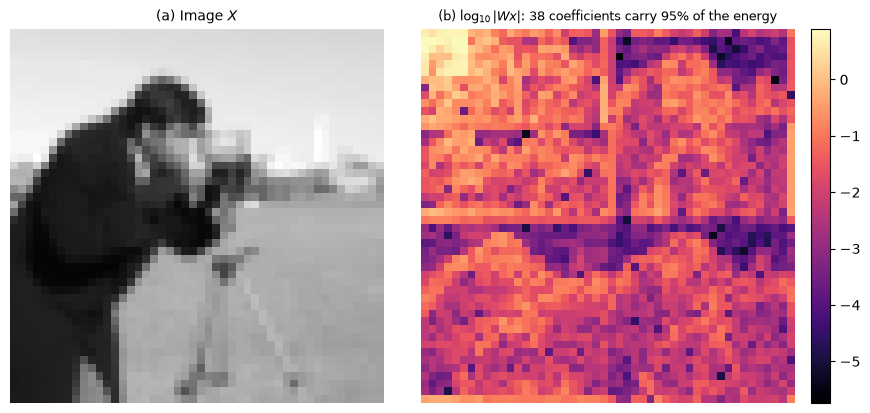

In [13]:
import pywt

# Orthonormal wavelet transform W and its inverse (periodization => exact shape).
WAVELET, LEVEL = "db2", 3
coeffs = pywt.wavedec2(X, wavelet=WAVELET, level=LEVEL, mode="periodization")
coeff_arr, coeff_slices = pywt.coeffs_to_array(coeffs)


def W(z):
    C = pywt.wavedec2(z.reshape(h, w), wavelet=WAVELET, level=LEVEL,
                      mode="periodization")
    return pywt.coeffs_to_array(C)[0].ravel()


def Winv(u):
    C = pywt.array_to_coeffs(u.reshape(coeff_arr.shape), coeff_slices,
                             output_format="wavedec2")
    return pywt.waverec2(C, wavelet=WAVELET, mode="periodization").ravel()


# Orthonormality check: ||Wv|| = ||v|| and Winv(Wv) = v.
v = np.random.default_rng(0).standard_normal(N)
print(f"orthonormality: | ||Wv|| - ||v|| | = "
      f"{abs(np.linalg.norm(W(v)) - np.linalg.norm(v)):.1e}, "
      f"max|W^-1 W v - v| = {np.abs(Winv(W(v)) - v).max():.1e}")

# Sparsity of the image in this basis.
c = W(x)
energy = np.sort(c**2)[::-1]
cum = np.cumsum(energy) / energy.sum()
print(f"coefficients for 95% of the energy: {np.searchsorted(cum, 0.95) + 1} of {N}")
print(f"coefficients for 99% of the energy: {np.searchsorted(cum, 0.99) + 1} of {N}")
print(f"fraction of coefficients with |c| < 1e-3: {np.mean(np.abs(c) < 1e-3):.1%}")


# L = ||A^T A||_2 by power iteration, then eta = 1 / L.
def power_iteration(M, n_iter=60):
    v = np.random.default_rng(1).standard_normal(M.shape[1])
    v /= np.linalg.norm(v)
    for _ in range(n_iter):
        v = M.T @ (M @ v)
        v /= np.linalg.norm(v)
    return v @ (M.T @ (M @ v))


L = power_iteration(A)
eta = 1.0 / L
print(f"L = ||A^T A||_2 ~ {L:.4f}, step eta = 1/L = {eta:.4f}")


def soft(u, alpha):
    """Element-wise soft-thresholding: the proximal operator of alpha*||u||_1."""
    return np.sign(u) * np.maximum(np.abs(u) - alpha, 0.0)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2))

ax1.imshow(X, cmap="gray", vmin=0, vmax=1)
ax1.set_title("(a) Image $X$", fontsize=10)
ax1.axis("off")

im = ax2.imshow(np.log10(np.abs(coeff_arr) + 1e-6), cmap="magma")
ax2.set_title(f"(b) $\\log_{{10}}|Wx|$: {np.searchsorted(cum, 0.95) + 1} "
              f"coefficients carry 95% of the energy", fontsize=9)
ax2.axis("off")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

fig.tight_layout()



The transform is orthonormal to machine precision and $L\approx0.99$, so $\eta\approx1.01$. The image is indeed sparse in this basis: 38 of the 2304 coefficients carry $95\%$ of the energy and 163 carry $99\%$, while many detail coefficients are tiny. Figure 4 shows the concentration: the large coefficients sit in the coarse approximation block (top-left) and along the main edges.

### 2. Choice of the regularization parameter $\lambda$

We run ISTA for a budget of 250 iterations and sweep $\lambda$ over several decades. The step size is fixed at $\eta=1/L$.


In [14]:
def ista(lam, n_iter, track=False):
    """ISTA for 0.5*||Ax-y||^2 + lam*||Wx||_1."""
    xk = np.zeros(N)
    hist = {"it": [], "psnr": [], "ssim": [], "obj": []}
    best = {"it": 0, "psnr": -np.inf, "ssim": 0.0, "x": None}

    for it in range(1, n_iter + 1):
        # Gradient step on the data term.
        z = xk - eta * (A.T @ (A @ xk - y_eta))
        # Proximal step: soft-threshold in the wavelet domain.
        xk = Winv(soft(W(z), eta * lam))

        if track and (it == 1 or it % 10 == 0):
            r = A @ xk - y_eta
            p = psnr(X, xk.reshape(h, w), data_range=1.0)
            q = ssim(X, xk.reshape(h, w), data_range=1.0)
            hist["it"].append(it)
            hist["psnr"].append(p)
            hist["ssim"].append(q)
            hist["obj"].append(0.5 * r @ r + lam * np.abs(W(xk)).sum())
            if p > best["psnr"]:
                best = {"it": it, "psnr": p, "ssim": q, "x": xk.copy()}

    return xk, hist, best


LAMBDAS = np.array([1e-5, 2e-5, 3e-5, 5e-5, 1e-4, 3e-4, 1e-3])
N_ITER_SWEEP = 250

sweep = []
for lam in LAMBDAS:
    xh, _, _ = ista(lam, N_ITER_SWEEP)
    sweep.append((lam,
                  psnr(X, xh.reshape(h, w), data_range=1.0),
                  ssim(X, xh.reshape(h, w), data_range=1.0)))

print(f"{'lambda':>8s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 28)
for lam, p, q in sweep:
    print(f"{lam:8.0e} {p:10.2f} {q:7.3f}")

best_lam = max(sweep, key=lambda row: row[1])[0]
print(f"\nBest lambda by PSNR: {best_lam:.1e}")


  lambda  PSNR (dB)    SSIM
----------------------------
   1e-05      28.05   0.874
   2e-05      28.05   0.877
   3e-05      28.05   0.879
   5e-05      28.02   0.883
   1e-04      27.85   0.886
   3e-04      26.98   0.877
   1e-03      25.58   0.853

Best lambda by PSNR: 2.0e-05



The PSNR is remarkably flat for $\lambda\in[10^{-5},5\times10^{-5}]$ and then decreases as $\lambda$ grows: with $\lambda=10^{-3}$ the image is over-smoothed and the PSNR drops to $25.6$ dB. The SSIM prefers slightly larger values (around $10^{-4}$), because a bit more shrinkage removes noise that the PSNR alone does not penalize much. This is the usual bias-variance tradeoff: too small $\lambda$ keeps the noise, too large $\lambda$ erases texture.

### 3. Effect of the number of iterations: early stopping

We now fix the best $\lambda$ and run for 1500 iterations, recording the objective, PSNR and SSIM every 10 iterations.


ISTA: lambda = 2.0e-05
best iteration =  260   PSNR = 28.05 dB   SSIM = 0.876
last iterate (1500 iterations): PSNR = 26.17 dB, SSIM = 0.752


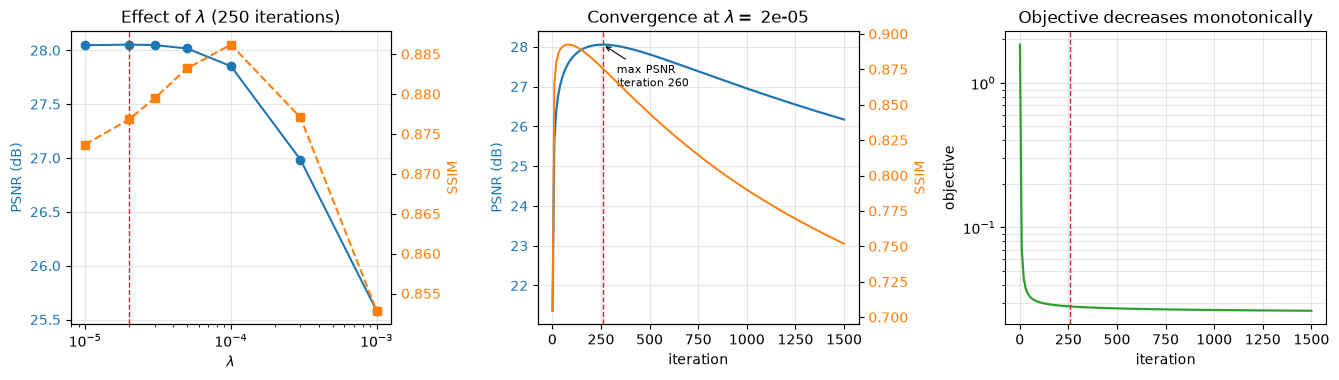

In [15]:
N_ITER_MAX = 1500
x_last, hist, best = ista(best_lam, N_ITER_MAX, track=True)

best_it = best["it"]
x_ista = best["x"]

print(f"ISTA: lambda = {best_lam:.1e}")
print(f"best iteration = {best_it:4d}   PSNR = {best['psnr']:.2f} dB   "
      f"SSIM = {best['ssim']:.3f}")
print(f"last iterate ({N_ITER_MAX} iterations): "
      f"PSNR = {hist['psnr'][-1]:.2f} dB, SSIM = {hist['ssim'][-1]:.3f}")

lams_sweep = np.array([row[0] for row in sweep])
psnr_sweep = np.array([row[1] for row in sweep])
ssim_sweep = np.array([row[2] for row in sweep])

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# (a) Effect of lambda.
ax = axes[0]
ax.semilogx(lams_sweep, psnr_sweep, "o-", color="tab:blue")
ax.axvline(best_lam, color="tab:red", ls="--", lw=1)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Effect of $\lambda$ (250 iterations)")
ax_b = ax.twinx()
ax_b.semilogx(lams_sweep, ssim_sweep, "s--", color="tab:orange")
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")

# (b) PSNR and SSIM versus iterations.
ax = axes[1]
ax.plot(hist["it"], hist["psnr"], color="tab:blue", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Convergence at $\lambda=$" + f" {best_lam:.0e}")
ax_b = ax.twinx()
ax_b.plot(hist["it"], hist["ssim"], color="tab:orange", lw=1.4)
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")
ax.annotate(f"max PSNR\niteration {best_it}", (best_it, best["psnr"]),
            textcoords="offset points", xytext=(10, -30), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8))

# (c) Objective decreases monotonically.
ax = axes[2]
ax.semilogy(hist["it"], hist["obj"], color="tab:green", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("objective")
ax.set_title("Objective decreases monotonically")
ax.grid(alpha=0.3, which="both")

fig.tight_layout()



**Figure 5.** (a) PSNR and SSIM as a function of $\lambda$ at 250 iterations. (b) At the best $\lambda$, the PSNR peaks at iteration 260 and then decreases, while the SSIM peaks even earlier (around 100 iterations). (c) The objective of the optimization problem decreases monotonically over the whole run.

Panel (c) is the key to the apparent contradiction: ISTA is solving its optimization problem correctly (the objective always goes down), but the $\ell_1$ model is only an approximation of the true image. After roughly 250 iterations the useful wavelet coefficients have already been recovered, and further iterations mainly fit the noise that the model cannot distinguish from signal. **The iteration count acts as an additional regularization parameter (early stopping).**

The best $\lambda$ and the best iteration are again chosen by maximizing PSNR on this example (an oracle choice), as in Section 3.1. In practice one would use the discrepancy principle, cross-validation or a fixed computational budget.



### 4. Comparison with the linear reconstructions

We now compare ISTA at its best configuration against the methods of Section 3.1: the blurred data, the direct pseudoinverse, Tikhonov and TSVD.


method                    PSNR (dB)    SSIM
--------------------------------------------
blurred measurement           23.49   0.812
direct inversion             -86.90   0.000
Tikhonov                      27.87   0.853
TSVD                          27.17   0.790
ISTA, 10 iterations           25.64   0.865
ISTA, 260 iterations          28.05   0.876


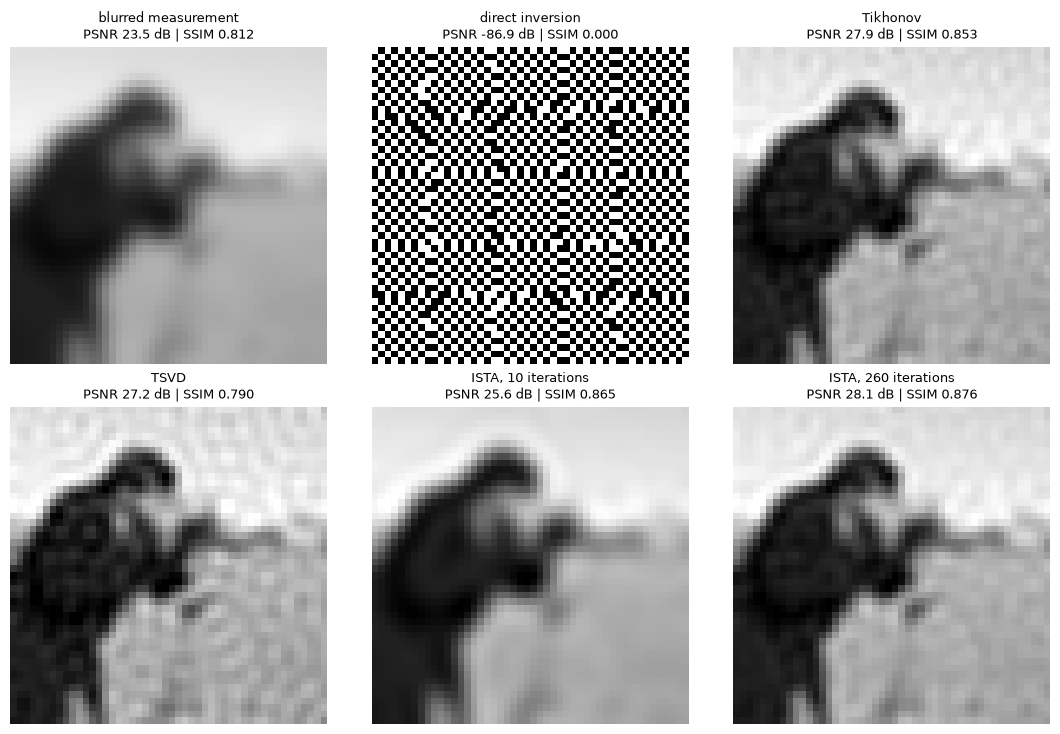

In [16]:
xh10, _, _ = ista(best_lam, 10)

methods = [
    ("blurred measurement", y),
    ("direct inversion", x_noisy),
    ("Tikhonov", x_tik),
    ("TSVD", x_tsvd),
    ("ISTA, 10 iterations", xh10),
    (f"ISTA, {best_it} iterations", x_ista),
]

print(f"{'method':24s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 44)
for name, z in methods:
    Z = z.reshape(h, w)
    print(f"{name:24s} {psnr(X, Z, data_range=1.0):10.2f} "
          f"{ssim(X, Z, data_range=1.0):7.3f}")

fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (name, z) in zip(axes.ravel(), methods):
    ax.imshow(np.clip(z.reshape(h, w), 0, 1), cmap="gray", vmin=0, vmax=1)
    p = psnr(X, z.reshape(h, w), data_range=1.0)
    q = ssim(X, z.reshape(h, w), data_range=1.0)
    ax.set_title(f"{name}\nPSNR {p:.1f} dB | SSIM {q:.3f}", fontsize=9)
    ax.axis("off")
fig.tight_layout()



**Figure 6.** From top-left to bottom-right: the blurred measurement, the unstable direct inversion, the best Tikhonov and TSVD reconstructions, ISTA after only 10 iterations, and ISTA at its best iteration. ISTA removes most of the noise of the linear reconstructions while keeping the main edges; the residual error is mostly the information that the blur destroyed.

### Conclusions for this exercise

1. **Without a prior, the inversion amplifies noise.** The direct pseudoinverse gives PSNR $-86.9$ dB; Tikhonov and TSVD stabilize it but still leave a noisy, ringy image. The wavelet prior suppresses most of that noise because it forces the solution to be sparse in a basis where the image is concentrated in a few coefficients.
2. **Soft-thresholding is the prior in action.** Small wavelet coefficients are dominated by noise and are set to zero; large coefficients carry edges and texture and are only shrunk by $\eta\lambda$. That is why the reconstruction keeps structure while removing high-frequency noise.
3. **$\lambda$ controls the bias-variance tradeoff.** Too small ($\lesssim10^{-5}$) leaves noise; too large ($\gtrsim3\times10^{-4}$) over-smooths and erases texture. PSNR is flat over a decade of useful values, while SSIM prefers slightly stronger regularization.
4. **Iterations also regularize.** The objective decreases monotonically, but PSNR peaks at about 260 iterations and then declines (26.2 dB at 1500). Solving the model too accurately overfits the noise, so early stopping is a second regularization knob. A faster alternative is FISTA, which reaches a similar point in far fewer iterations.
5. **The gain over Tikhonov is real but modest.** ISTA reaches $28.05$ dB and SSIM $0.876$, against $27.87$ dB and $0.853$ for Tikhonov and $27.17$ dB and $0.790$ for TSVD. Since 1394 singular directions are already below the noise level, no method can recover that information; the prior improves the structure, not the missing frequencies.
6. **Other priors.** A total-variation prior would favor piecewise-smooth images and preserve sharp edges better, at the cost of a more involved proximal step (Chambolle's algorithm) and possible staircasing. Learned priors (denoisers, networks) can capture richer image statistics than a fixed wavelet basis.
